# Lab01 — Spam Classification

Notebook tái lập tám bước thực nghiệm từ dữ liệu gốc đến đánh giá test. Chạy từ trên xuống, chọn kernel Python có thư viện trong requirements.txt.

## 1. Mục tiêu và thiết lập

**Giải thích.** Phân loại email ham = 0, spam = 1 bằng Logistic Regression, Linear SVM và Multinomial Naive Bayes tự cài. Chọn cấu hình theo Macro-F1 validation, theo dõi Accuracy, Precision, Recall, F1 spam và FP/FN. YAML quy định cách chia validation, TF-IDF và lưới tham số. Các kết quả được lưu riêng theo lần mở notebook.

In [1]:
from pathlib import Path
import sys
import json
from uuid import uuid4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import yaml
from sklearn.model_selection import train_test_split

repo = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "Lab01/src/preprocessing.py").is_file()), None)
if repo is None:
    raise RuntimeError("Open this notebook inside the repository.")
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
from Lab01.src.preprocessing import main as clean_data, split_clean_data, build_vectorizer
from Lab01.src.train import train_model
from Lab01.src.tuning import select_models, threshold_metrics
from Lab01.src.evaluate import evaluate, save_errors
from Lab01.algorithms import LogisticRegression, LinearSVM, MultinomialNaiveBayes

lab = repo / "Lab01"
output = lab / "results" / ("notebook_full_" + uuid4().hex[:8])
output.mkdir(parents=True)
prep = output / "preprocessing"
config = yaml.safe_load((lab / "src/config.yaml").read_text(encoding="utf-8"))
(output / "config.yaml").write_text(yaml.safe_dump(config), encoding="utf-8")
print("Output:", output)
print(json.dumps(config, ensure_ascii=False, indent=2))


Output: E:\ML_Nhóm6\Lab01\results\notebook_full_67f00120
{
  "validation": {
    "fraction": 0.2,
    "seed": 43
  },
  "logistic_regression": {
    "threshold": null,
    "threshold_candidates": [],
    "learning_rate": [
      0.1,
      1.0,
      5.0
    ],
    "n_iterations": [
      1000,
      3000
    ]
  },
  "svm": {
    "candidates": [
      {
        "learning_rate": 0.01,
        "n_iterations": 1000,
        "C": 1
      },
      {
        "learning_rate": 0.05,
        "n_iterations": 3000,
        "C": 1
      },
      {
        "learning_rate": 0.05,
        "n_iterations": 1000,
        "C": 10
      },
      {
        "learning_rate": 0.1,
        "n_iterations": 3000,
        "C": 10
      },
      {
        "learning_rate": 0.01,
        "n_iterations": 1000,
        "C": 50
      },
      {
        "learning_rate": 0.05,
        "n_iterations": 3000,
        "C": 50
      },
      {
        "learning_rate": 0.01,
        "n_iterations": 3000,
        "C": 100
    

**Kết quả và nhận xét.** Ô trên hiển thị cấu hình thực sự dùng trong lần chạy. Giữ nguyên cấu hình từ đầu đến cuối để bảng tuning và mô hình lưu nhất quán.

## 2. Dữ liệu

**Giải thích.** Đọc CSV gốc, khảo sát phân bố nhãn, làm sạch theo hàm trong src, loại nội dung rỗng và bản trùng. Kiểm tra xung đột nhãn trước khi chia.

Raw shape: (5171, 4)
label_num
0    3672
1    1499
Missing values:
 Unnamed: 0    0
label         0
text          0
label_num     0
raw=5171 invalid=0 empty_after_cleaning=0 duplicates=287 remaining=4884
{0: 3427, 1: 1457}
Example: free click prize
Cleaning summary: {
  "original_rows": 5171,
  "invalid_rows_removed": 0,
  "empty_rows_removed": 0,
  "duplicates_removed": 287,
  "clean_rows": 4884
}

 email_id  label_num                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 

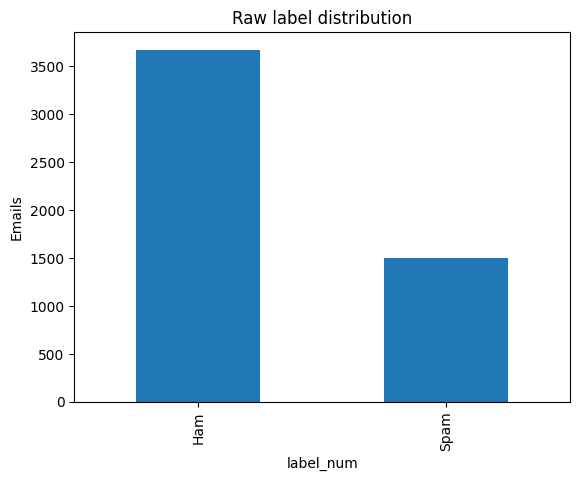

In [2]:
raw = pd.read_csv(lab / "Data/raw/spam_ham_dataset.csv", keep_default_na=False)
print("Raw shape:", raw.shape)
print(raw["label_num"].value_counts().sort_index().to_string())
print("Missing values:\n", raw.isna().sum().to_string())
raw["label_num"].value_counts().rename(index={0:"Ham",1:"Spam"}).plot.bar(title="Raw label distribution")
plt.ylabel("Emails")
plt.show()
clean_data(prep)
cleaned = pd.read_csv(prep / "cleaned_raw.csv", keep_default_na=False)
print("Cleaning summary:", (prep / "summary.json").read_text())
print(cleaned[["email_id", "label_num", "text_clean"]].head().to_string(index=False))


**Kết quả và nhận xét.** So sánh original_rows, duplicates_removed và clean_rows ở đầu ra. Nhãn đa số có thể làm Accuracy cao dù bỏ lọt spam, vì vậy dùng thêm Macro-F1 và Recall spam.

## 3. Chia tập và TF-IDF

**Giải thích.** Chia test một lần với seed 42. Tách subtrain/validation từ train ban đầu theo YAML. Chỉ fit TF-IDF trên subtrain. Test được giữ riêng đến mục 7.

In [3]:
split_clean_data(prep)
development = pd.read_csv(prep / "train_clean.csv", keep_default_na=False)
test = pd.read_csv(prep / "test_clean.csv", keep_default_na=False).reset_index(drop=True)
subtrain, validation = train_test_split(
    development, test_size=config["validation"]["fraction"],
    random_state=config["validation"]["seed"], stratify=development["label_num"])
subtrain, validation = subtrain.reset_index(drop=True), validation.reset_index(drop=True)
assert not set(subtrain.email_id) & set(validation.email_id)
assert not set(development.email_id) & set(test.email_id)
vectorizer = build_vectorizer(config.get("features"))
X = vectorizer.fit_transform(subtrain.text_clean)
V = vectorizer.transform(validation.text_clean)
y = subtrain.label_num.to_numpy()
actual = validation.label_num.to_numpy()
subtrain.to_csv(prep / "subtrain_clean.csv", index=False)
validation.to_csv(prep / "validation_clean.csv", index=False)
print(pd.DataFrame([{"split":n,"rows":len(f),"ham":int((f.label_num==0).sum()),
                     "spam":int((f.label_num==1).sum())}
                    for n,f in [("subtrain",subtrain),("validation",validation),("test",test)]]).to_string(index=False))
print("X:", X.shape, "V:", V.shape, "| TF-IDF fit split: subtrain")


train: 3907 emails, {0: 2741, 1: 1166}
test: 977 emails, {0: 686, 1: 291}
     split  rows  ham  spam
  subtrain  3125 2192   933
validation   782  549   233
      test   977  686   291
X: (3125, 50000) V: (782, 50000) | TF-IDF fit split: subtrain


**Kết quả và nhận xét.** Số dòng và tỷ lệ nhãn của ba tập hiện ở bảng trên. Cùng bộ từ vựng giúp các cột train/validation có cùng ý nghĩa. Test chưa được dùng để chọn đặc trưng hoặc tham số.

## 4. Baseline

**Giải thích.** Huấn luyện ba cấu hình mặc định trên cùng subtrain và đánh giá validation. Đây là mốc trước tuning.

In [4]:
baselines = {"logistic_regression":LogisticRegression(),
             "svm":LinearSVM(), "naive_bayes":MultinomialNaiveBayes()}
baseline_rows = []
for name, model in baselines.items():
    train_model(model, X, y)
    score = evaluate(actual, model.predict(V), validation.email_id,
                     output / "baseline_validation" / name)
    baseline_rows.append({"model":name, **score})
baseline_results = pd.DataFrame(baseline_rows)
baseline_results.to_csv(output / "baseline_validation.csv", index=False)
print(baseline_results.to_string(index=False))


              model  accuracy  macro_f1  ham_as_spam  spam_as_ham  spam_precision  spam_recall  spam_f1
logistic_regression  0.702046  0.412472            0          233             0.0     0.000000 0.000000
                svm  0.702046  0.412472            0          233             0.0     0.000000 0.000000
        naive_bayes  0.947570  0.933766            0           41             1.0     0.824034 0.903529


**Kết quả và nhận xét.** Đọc Macro-F1 cùng FP/FN trong bảng. Cấu hình mặc định yếu có thể do learning rate, số vòng hoặc ngưỡng chưa phù hợp.

## 5. Thực nghiệm

**Giải thích.** Trước tiên khảo sát ba bộ TF-IDF với Naive Bayes alpha = 1 cố định. Sau đó chạy tuning ba mô hình theo YAML trên cùng validation. Khảo sát đặc trưng là thí nghiệm riêng, cấu hình features trong YAML vẫn quyết định bộ TF-IDF dùng cho tuning chính.

In [5]:
feature_rows = []
for options in [
    {"analyzer":"word", "ngram_range":[1,1], "max_features":50000},
    {"analyzer":"word", "ngram_range":[1,2], "max_features":50000},
    {"analyzer":"char_wb", "ngram_range":[3,5], "max_features":50000},
]:
    candidate_vectorizer = build_vectorizer(options)
    candidate_X = candidate_vectorizer.fit_transform(subtrain.text_clean)
    candidate_V = candidate_vectorizer.transform(validation.text_clean)
    candidate = train_model(MultinomialNaiveBayes(alpha=1.0), candidate_X, y)
    score = evaluate(actual, candidate.predict(candidate_V), validation.email_id,
                     output / "feature_trials" / str(len(feature_rows)))
    feature_rows.append({"features":str(options), **score})
feature_results = pd.DataFrame(feature_rows)
feature_results.to_csv(output / "feature_comparison.csv", index=False)
print(feature_results.to_string(index=False))


                                                             features  accuracy  macro_f1  ham_as_spam  spam_as_ham  spam_precision  spam_recall  spam_f1
   {'analyzer': 'word', 'ngram_range': [1, 1], 'max_features': 50000}  0.907928  0.877860            0           72        1.000000     0.690987 0.817259
   {'analyzer': 'word', 'ngram_range': [1, 2], 'max_features': 50000}  0.947570  0.933766            0           41        1.000000     0.824034 0.903529
{'analyzer': 'char_wb', 'ngram_range': [3, 5], 'max_features': 50000}  0.955243  0.944581            4           31        0.980583     0.866953 0.920273


In [6]:
selection = select_models(development, output / "tuning")
assert selection.subtrain.email_id.tolist() == subtrain.email_id.tolist()
assert selection.validation.email_id.tolist() == validation.email_id.tolist()
trial_results = pd.read_csv(output / "tuning/validation.csv")
print(trial_results.drop(columns=["confusion_matrix"], errors="ignore").to_string(index=False))
svm_trials = pd.read_csv(output / "tuning/svm_study/all_thresholds.csv")
print("Total SVM threshold evaluations:", len(svm_trials))
print(svm_trials.sort_values("macro_f1", ascending=False).head(5).to_string(index=False))


              model           candidate_id  learning_rate  n_iterations  threshold  macro_f1  fit_seconds  spam_precision  spam_recall  spam_f1  predicted_spam  alpha     C  class_weight  fn  fp  accuracy
logistic_regression                      0           0.10        1000.0   0.338152  0.962470     0.644878        0.919355     0.978541 0.948025             248    NaN   NaN           NaN NaN NaN       NaN
logistic_regression                      1           0.10        3000.0   0.381724  0.966936     1.791134        0.927126     0.982833 0.954167             247    NaN   NaN           NaN NaN NaN       NaN
logistic_regression                      2           1.00        1000.0   0.427161  0.980347     0.588270        0.954545     0.991416 0.972632             242    NaN   NaN           NaN NaN NaN       NaN
logistic_regression                      3           1.00        3000.0   0.470298  0.992386     1.815901        0.983051     0.995708 0.989339             236    NaN   NaN        

**Kết quả và nhận xét.** Bảng đặc trưng giữ alpha cố định để so sánh cách biểu diễn. Bảng tuning thử siêu tham số và chọn ngưỡng LR/SVM. Số dòng all_thresholds cho biết tổng phép chấm ngưỡng SVM, file lưu đầy đủ cả các ứng viên kém hơn.

## 6. Lựa chọn cuối

**Giải thích.** Giữ lại các mô hình đã học trên subtrain để bảo toàn điểm và ngưỡng được chọn trên validation, phù hợp pipeline hiện tại. Chọn một mô hình đại diện theo Macro-F1 validation, đồng thời chốt cả ba mô hình để báo cáo test.

In [7]:
chosen = json.loads((output / "tuning/selection.json").read_text(encoding="utf-8"))
validation_rows = []
for name, model in selection.models.items():
    score = evaluate(actual, model.predict(selection.V), validation.email_id,
                     output / "final_validation" / name)
    validation_rows.append({"model":name, **score})
validation_results = pd.DataFrame(validation_rows)
winner = validation_results.sort_values("macro_f1", ascending=False, kind="stable").iloc[0]["model"]
print("Selected parameters:", json.dumps(chosen["selected"], ensure_ascii=False, indent=2))
print(validation_results.to_string(index=False))
print("Representative model selected on validation:", winner)


Selected parameters: {
  "logistic_regression": {
    "learning_rate": 5.0,
    "n_iterations": 1000,
    "threshold": 0.4509449095570793
  },
  "naive_bayes": {
    "alpha": 0.01
  },
  "svm": {
    "learning_rate": 0.01,
    "n_iterations": 3000,
    "C": 100,
    "class_weight": null,
    "threshold": -0.6620115722742366
  }
}
              model  accuracy  macro_f1  ham_as_spam  spam_as_ham  spam_precision  spam_recall  spam_f1
logistic_regression  0.996164  0.995432            3            0        0.987288     1.000000 0.993603
        naive_bayes  0.987212  0.984754            6            4        0.974468     0.982833 0.978632
                svm  0.985934  0.983291            8            3        0.966387     0.987124 0.976645
Representative model selected on validation: logistic_regression


**Kết quả và nhận xét.** Ngưỡng là một phần của mô hình được chốt. Baseline và mô hình tuned đều học từ subtrain. Sau bước này giữ nguyên đặc trưng, tham số và ngưỡng khi đánh giá test.

## 7. Đánh giá test

**Giải thích.** Transform test bằng TF-IDF của selection, gọi evaluate để tính chỉ số và vẽ ma trận. save_errors lưu email sai, điểm, nhãn và loại lỗi. Chỉ so sánh test sau khi lựa chọn ở mục 6 đã hoàn tất.

              model  accuracy  macro_f1  ham_as_spam  spam_as_ham  spam_precision  spam_recall  spam_f1
logistic_regression  0.991812  0.990231            5            3        0.982935     0.989691 0.986301
        naive_bayes  0.982600  0.979302           11            6        0.962838     0.979381 0.971039
                svm  0.984647  0.981807           12            3        0.960000     0.989691 0.974619
logistic_regression | error counts: {'FP': 5, 'FN': 3}
 email_id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

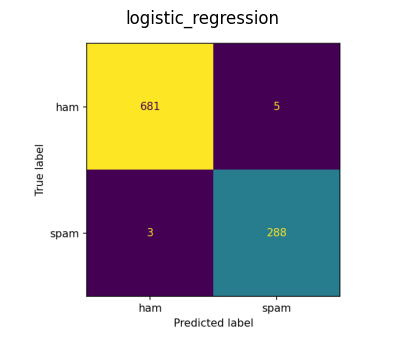

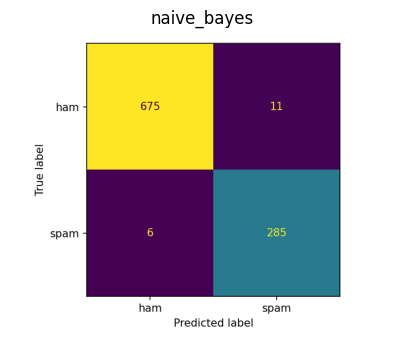

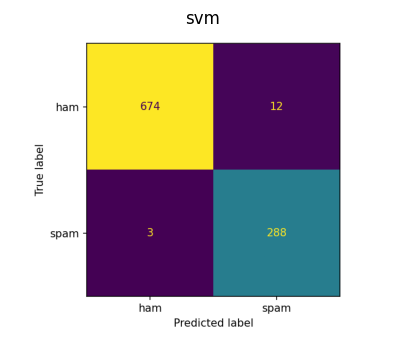

In [8]:
X_test = selection.vectorizer.transform(test.text_clean)
test_rows = []
for name, model in selection.models.items():
    destination = output / "test" / name
    score = evaluate(test.label_num.to_numpy(), model.predict(X_test), test.email_id, destination)
    save_errors(model, X_test, test, destination)
    test_rows.append({"model":name, **score})
    image = plt.imread(destination / "confusion_matrix.png")
    plt.figure(figsize=(5,4))
    plt.imshow(image)
    plt.axis("off")
    plt.title(name)
    plt.show()
test_results = pd.DataFrame(test_rows)
test_results.to_csv(output / "test_metrics.csv", index=False)
print(test_results.to_string(index=False))
for name in selection.models:
    errors = pd.read_csv(output / "test" / name / "errors.csv")
    print(name, "| error counts:", errors.error_type.value_counts().to_dict())
    print(errors.head(3).to_string(index=False))


**Kết quả và nhận xét.** Ma trận và FP/FN cho biết cân bằng giữa bỏ lọt spam và gắn nhầm ham. Các ví dụ email sai là quan sát trên test. Nếu dùng chúng để sửa mô hình, cần đánh giá phiên bản sau trên tập giữ riêng mới.

## 8. Lưu kết quả và kết luận

**Giải thích.** Lưu mô hình, TF-IDF, cấu hình và tổng kết vào thư mục notebook riêng để có thể nạp lại. Xuất so sánh baseline/tuned trên validation cùng kết quả test.

In [9]:
model_dir = output / "models"
model_dir.mkdir(exist_ok=True)
joblib.dump(selection.vectorizer, model_dir / "tfidf_vectorizer.joblib")
for name, model in selection.models.items():
    joblib.dump(model, model_dir / f"{name}.joblib")
reloaded = joblib.load(model_dir / f"{winner}.joblib")
assert np.array_equal(reloaded.predict(X_test), selection.models[winner].predict(X_test))
comparison = baseline_results[["model","macro_f1"]].merge(
    validation_results[["model","macro_f1"]], on="model", suffixes=("_baseline","_tuned"))
comparison.to_csv(output / "validation_before_after.csv", index=False)
conclusion = {
    "representative_model":str(winner),
    "selected_on":"validation_macro_f1",
    "fit_split":"subtrain",
    "refit":False,
    "subtrain_rows":len(subtrain), "validation_rows":len(validation), "test_rows":len(test),
    "parameters":chosen["selected"],
    "test_metrics":test_results.to_dict(orient="records"),
}
(output / "conclusion.json").write_text(json.dumps(conclusion, ensure_ascii=False, indent=2), encoding="utf-8")
print(comparison.to_string(index=False))
print("Selected on validation:", winner)
print("All outputs:", output)
print("Joblib round-trip predictions verified.")


              model  macro_f1_baseline  macro_f1_tuned
logistic_regression           0.412472        0.995432
                svm           0.412472        0.983291
        naive_bayes           0.933766        0.984754
Selected on validation: logistic_regression
All outputs: E:\ML_Nhóm6\Lab01\results\notebook_full_67f00120
Joblib round-trip predictions verified.


**Kết quả và nhận xét.** conclusion.json ghi mô hình đại diện, cấu hình và điểm test thực tế. Kết quả thuộc một cách chia dữ liệu cố định. Notebook có thể chạy lại từ đầu để tạo thư mục kết quả mới. Khi thay đổi đặc trưng, cần chọn lại cấu hình trên validation trước khi đánh giá phiên bản test tiếp theo.

**Nhận xét lần chạy đã kiểm tra.** Mô hình đại diện theo validation là logistic_regression. logistic_regression đạt Macro-F1 test 99.02%, FP = 5, FN = 3. naive_bayes đạt Macro-F1 test 97.93%, FP = 11, FN = 6. svm đạt Macro-F1 test 98.18%, FP = 12, FN = 3. Các nhận xét này thuộc lần chạy notebook_full_67f00120. Khi chạy lại với cấu hình khác, đọc bảng đầu ra và conclusion.json mới.